## Ejercicio 4

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [10]:
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = X_fantoma.shape[0]
x_fantoma = X_fantoma.reshape(-1)

In [11]:
def mascara_rayo(n, direccion, s):
    alfa = direccion[0]
    beta = direccion[1]
    matriz = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            if alfa * i + beta * j == s:
                matriz[i][j] = 1
    return matriz


def matriz_proyeccion(n, direcciones):
    filas_A = []
    rayos = []

    for direccion in direcciones:
        alfa = direccion[0]
        beta = direccion[1]
        valores_s = set()

        for i in range(n):
            for j in range(n):
                valores_s.add(alfa * i + beta * j)

        for s in sorted(valores_s):
            mascara = mascara_rayo(n, direccion, s)
            filas_A.append(mascara.reshape(-1))
            rayos.append((direccion, s))

    A = np.array(filas_A, dtype=float)
    return A, rayos

### Inciso a)

Para una matriz con 64 columnas, el teorema de rango y nulidad establece que

$$\operatorname{rango}(A)+\dim(\operatorname{Nul}(A))=64.$$

Una imagen se determina de manera única a partir de mediciones compatibles si
$\operatorname{rango}(A)=64$. En ese caso el espacio nulo contiene solamente al vector cero.
Si existe $v\ne0$ tal que $Av=0$, entonces

$$
\dim(\operatorname{Nul}(A)) > 0
\quad\Longrightarrow\quad
\operatorname{rango}(A) < 64.
$$

Si $x$ es una solución, $x+v$ también lo es, porque

$$A(x+v)=Ax+Av=Ax.$$

Por lo tanto, existen imágenes distintas que producen las mismas mediciones y la reconstrucción no es única. Tener al menos 64 filas es necesario para alcanzar rango 64, pero esa cantidad de filas por sí sola no garantiza alcanzarlo.

### Inciso b)

In [12]:
D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]

A2, rayos2 = matriz_proyeccion(n, D2)
A4, rayos4 = matriz_proyeccion(n, D4)
A7, rayos7 = matriz_proyeccion(n, D7)

In [13]:
matrices = [A2, A4, A7]
nombres = ["A2", "A4", "A7"]

for i in range(len(matrices)):
    # Para cada matriz obtenemos su rango, la dimension del espacio nulo y la redundancia
    A = matrices[i]
    rango = np.linalg.matrix_rank(A)
    nulidad = A.shape[1] - rango
    redundancia = A.shape[0] - rango

    print("Matriz:", nombres[i])
    print("Dimensiones:", A.shape)
    print("Rango:", rango)
    print("Dimensión del espacio nulo:", nulidad)
    print("Mediciones redundantes:", redundancia)

    if nulidad == 0:
        print("La imagen se puede determinar de manera única.")
    else:
        print("La imagen no se puede determinar de manera única.")

    print()

Matriz: A2
Dimensiones: (16, 64)
Rango: 15
Dimensión del espacio nulo: 49
Mediciones redundantes: 1
La imagen no se puede determinar de manera única.

Matriz: A4
Dimensiones: (46, 64)
Rango: 39
Dimensión del espacio nulo: 25
Mediciones redundantes: 7
La imagen no se puede determinar de manera única.

Matriz: A7
Dimensiones: (119, 64)
Rango: 64
Dimensión del espacio nulo: 0
Mediciones redundantes: 55
La imagen se puede determinar de manera única.



`A2` tiene 16 filas y rango 15; `A4` tiene 46 filas y rango 39; `A7` tiene 119 filas y rango 64.
Las nulidades son 49, 25 y 0, respectivamente. Solamente `A7` permite recuperar una imagen
de manera única en el modelo sin ruido.

En los tres casos hay mediciones redundantes porque la cantidad de filas supera al rango.

### Inciso c)

Buscamos un vector $v$ distinto de cero que cumpla $A_4v=0$, es decir, una solución no trivial del sistema homogéneo. Para encontrarlo usamos la descomposición en valores singulares (SVD):

$$A_4=U\Sigma V^T.$$

$\Sigma$ (sigma mayúscula) es una matriz de $46\times64$, como $A_4$. Tiene los valores singulares en la diagonal y ceros en las demás posiciones. $U$ y $V$ son matrices ortogonales.

La función de NumPy devuelve tres resultados:

- `U`: la matriz $U$ de la descomposición.
- `S`: un arreglo con los valores singulares que se colocan en la diagonal de $\Sigma$. Esos valores se devuelven en un arreglo, en lugar de devolver toda la matriz $\Sigma$.
- `Vt`: la matriz $V^T$, es decir, la transpuesta de $V$. Por eso, cada columna de $V$ aparece como una fila de `Vt`.

Para elegir $v$, usamos `Vt`. Con `full_matrices=True` obtenemos la matriz completa de $64\times64$. Como $A_4$ tiene rango 39, su espacio nulo tiene dimensión $64-39=25$. En esta descomposición, las últimas 25 filas de `Vt` forman una base de ese espacio nulo: cualquiera de ellas sirve como $v$.

Elegimos la última fila con `Vt[-1]`

In [14]:
# Calculamos la SVD completa de A4.
U, S, Vt = np.linalg.svd(A4, full_matrices=True)

# Elegimos la última fila de Vt: un vector de la base del espacio nulo.
v = Vt[-1]

print("Norma de v:", np.linalg.norm(v))
print("Norma de A4 @ v:", np.linalg.norm(A4 @ v))

Norma de v: 1.0
Norma de A4 @ v: 1.168741631608234e-15


La norma de $v$ da aproximadamente 1, por lo que $v$ es un vector no nulo.

La norma de $A_4v$ da aproximadamente $1{,}58\times10^{-15}$, un valor muy cercano a cero. La pequeña diferencia se debe al redondeo numérico. Así comprobamos que el vector elegido cumple aproximadamente $A_4v=0$.

In [15]:
b4 = A4 @ x_fantoma # Calculamos las mediciones que produce el fantoma original.
gamma = 1 # gamma controla cuánto del vector v le sumamos a la imagen que debe ser distinto de cero.
x_alt = x_fantoma + gamma * v # Construimos una imagen alternativa sumando gamma * v al fantoma 
# vectorizado.

# Calculamos las mediciones que produce la imagen alternativa.
# Como A4 @ v es aproximadamente cero, esperamos obtener las mismas mediciones.
b_alt = A4 @ x_alt

# La norma de la diferencia mide la distancia entre los dos vectores de imagen.
# Si es mayor que cero, las imágenes son distintas.
print("Diferencia entre las imágenes:", np.linalg.norm(x_alt - x_fantoma))

# Esta distancia debería ser muy cercana a cero, aunque las imágenes sean distintas.
print("Diferencia entre las mediciones:", np.linalg.norm(b_alt - b4))

# allclose compara las componentes admitiendo pequeñas diferencias de redondeo.
# Esperamos False para las imágenes y True para las mediciones.
print("¿Las imágenes son iguales?", np.allclose(x_alt, x_fantoma))
print("¿Las mediciones coinciden?", np.allclose(b_alt, b4))

Diferencia entre las imágenes: 1.0
Diferencia entre las mediciones: 1.6845201750674206e-15
¿Las imágenes son iguales? False
¿Las mediciones coinciden? True


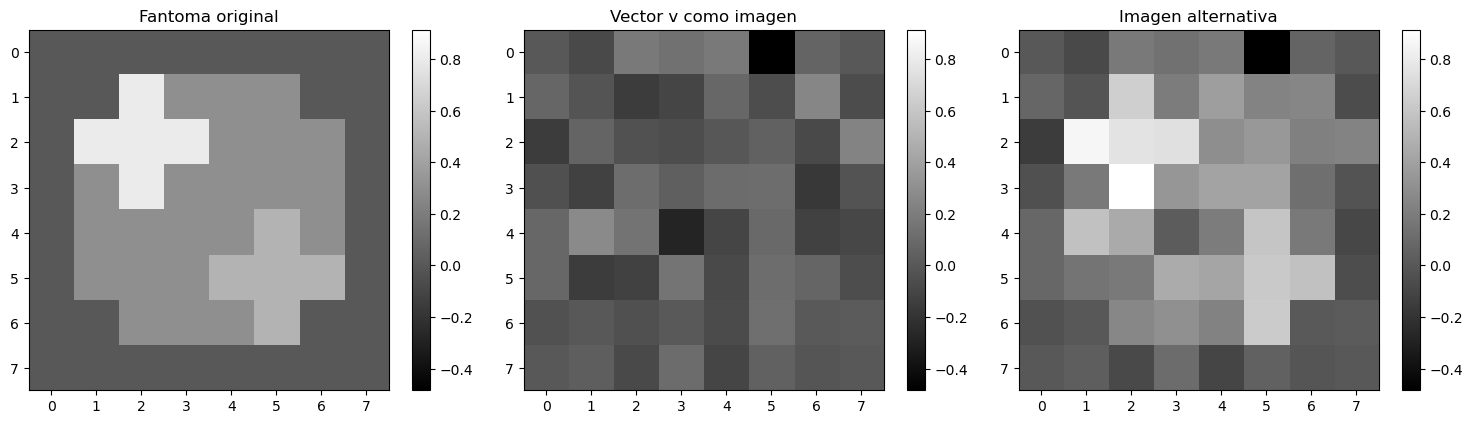

In [16]:
# Volvemos a organizar los vectores como matrices de n filas y n columnas.
# Así podemos visualizar tanto el vector v como la imagen alternativa.
V_imagen = v.reshape(n, n)
X_alt = x_alt.reshape(n, n)

# Buscamos el menor y el mayor valor entre las tres imágenes.
# Usamos esos mismos límites en todos los gráficos para comparar sus tonos de gris.
vmin = min(X_fantoma.min(), V_imagen.min(), X_alt.min())
vmax = max(X_fantoma.max(), V_imagen.max(), X_alt.max())

# Creamos una figura con tres gráficos, uno al lado del otro.
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

# Primer gráfico: el fantoma original.
# Guardamos el objeto de la imagen en im1 para agregar su barra de colores.
im1 = axs[0].imshow(X_fantoma, cmap="gray", vmin=vmin, vmax=vmax)
axs[0].set_title("Fantoma original")
fig.colorbar(im1, ax=axs[0])

# Segundo gráfico: los cambios que el vector v introduce en los píxeles.
im2 = axs[1].imshow(V_imagen, cmap="gray", vmin=vmin, vmax=vmax)
axs[1].set_title("Vector v como imagen")
fig.colorbar(im2, ax=axs[1])

# Tercer gráfico: la imagen alternativa obtenida al sumar gamma * v al fantoma.
im3 = axs[2].imshow(X_alt, cmap="gray", vmin=vmin, vmax=vmax)
axs[2].set_title("Imagen alternativa")
fig.colorbar(im3, ax=axs[2])

# Ajustamos los espacios entre los gráficos y mostramos la figura.
plt.tight_layout()
plt.show()

La imagen alternativa es distinta del fantoma, pero produce las mismas mediciones, salvo pequeñas diferencias de redondeo. Esto ocurre porque $A_4v=0$ y, por lo tanto,

$$A_4x_{alt}=A_4(x_{fantoma}+\gamma v)=A_4x_{fantoma}+\gamma A_4v=A_4x_{fantoma}.$$

Los cambios que introduce v se compensan al sumar los píxeles seleccionados por cada rayo. Por eso A4 no detecta esos cambios: los vectores de su espacio nulo representan información de la imagen que resulta invisible para esas mediciones.

Las tres imágenes usan la misma escala de grises. La imagen alternativa puede tener valores negativos porque estamos trabajando con el sistema lineal sin imponer restricciones sobre las atenuaciones.